# Лабораторна робота №4. Локальний запуск і оптимізація моделей

# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [1]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [3]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [4]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [5]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [6]:
QUESTION = "Яка столиця Франції?"

In [7]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [8]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [9]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.2 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 5.1 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [10]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 2.0 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 6.0 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [11]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [12]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [13]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [14]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [15]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [16]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,16.77,2.67,2.40,55.22,23.71
int8,4.42,5.01,5.59,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.75,2.81,2.76,55.34,29.79
int2,1.81,2.39,2.83,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

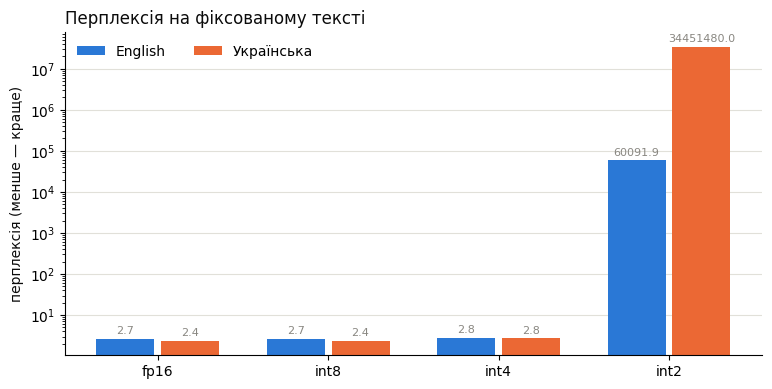

In [17]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [18]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [19]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "B", 2: "=", 3: "A", 4: "=", 5: "B"}

In [ ]:
import numpy as np
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in range(5)]
if all(v in ("A", "B", "=") for v in VOTES.values()):
    counts = {"fp16":0, "int4":0, "однаково":0}
    for i, v in VOTES.items():
        chosen = "однаково" if v == "=" else dict(zip("AB", BLIND_ORDER[i-1]))[v]
        counts[chosen] += 1
    print(counts)

{'fp16': 2, 'int4': 1, 'однаково': 2}


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [22]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

---
## 0. Опрацюйте демо-ноутбук лекції 5

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука в Google Colab.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (відповіді на питання потрібно написати у демо-ноутбуці)

### 1. У розділі 1.5 демо модель помиляється, рахуючи літеру «р» у слові «трансформер», — причому і без міркувань, і з ними. Поясніть, чому. Підтвердіть пояснення кодом.

**Відповідь:**
У слові «трансформер» 11 букв, літера «р» стоїть на позиціях 2, 8 і 11. У фактичному запуску без Thinking модель відповіла **1**, із Thinking — **2**. У першому випадку вона помилково оголосила, що «транс» не містить «р» і що у «формер» лише одна «р». У другому — відтворила слово з пропусками/заміною букв, а тому її підрахунок теж неправильний.

LLM працює з послідовністю токенів, а не з масивом окремих символів. Токени можуть охоплювати кілька букв чи частину слова. Модель вивчила статистичні зв'язки, а не гарантований алгоритм посимвольного обходу. Thinking не перетворює її на детермінований лічильник. Нижче — збережений точний підрахунок Python; окремий блок коду демонструє токенізацію.

In [23]:
word = 'трансформер'
print('Символи:', list(word))
print('Точний підрахунок:', word.count('р'))

Символи: ['т', 'р', 'а', 'н', 'с', 'ф', 'о', 'р', 'м', 'е', 'р']
Точний підрахунок: 3


In [ ]:
word = "трансформер"
print([(i,c) for i,c in enumerate(word,1) if c == "р"])

[(2, 'р'), (8, 'р'), (11, 'р')]


### 2. Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?

**Відповідь:**
| Варіант | PPL EN | PPL UK | chrF | BLEU |
|---|---:|---:|---:|---:|
| fp16 | 2,67 | 2,40 | 55,22 | 23,71 |
| int8 | 2,67 | 2,40 | 58,25 | 26,17 |
| int4 | 2,81 | 2,76 | 55,34 | 29,79 |
| int2 | 60 091,86 | 34 451 480,00 | 0,19 | 0,12 |

Найбільший стрибок — **int4 → int2**: chrF падає на 55,15 пункта, BLEU — на 29,67 пункта; PPL різко зростає. В int8 і int4 метрики не погіршуються монотонно: окремі переклади випадково стають ближчими до еталонів, тому BLEU навіть зростає. Це не означає, що int4 завжди якісніша за fp16. При int2 обидві перекладацькі метрики майже нульові.

In [25]:
print(summary.to_string())

      памʼять моделі, GB  пік VRAM, GB  tokens/s  перплексія, English  перплексія, Українська  chrF перекладу  BLEU перекладу
fp16                8.04          8.64     16.77                 2.67                    2.40           55.22           23.71
int8                4.42          5.01      5.59                 2.67                    2.40           58.25           26.17
int4                2.73          3.32      2.75                 2.81                    2.76           55.34           29.79
int2                1.81          2.39      2.83             60091.86             34451480.00            0.19            0.12


### 3. Чи однаково зростає перплексія для англійської й української? Порівняйте з висновком зі слайду «Де може просідати якість при квантизації».

**Відповідь:**
У межах кожної мови порівнюємо PPL з її власним fp16. За фактичним обчисленням у наступній клітинці int4 збільшила англійську PPL у 1,05 раза, українську — у 1,15 раза. Для int2 відносне зростання становить приблизно 22 476 та 14 353 762 рази відповідно. В українському тексті погіршення значно сильніше. Це узгоджується з тезою лекції про можливу вразливість менш представлених мов при квантизації. Однак один текст на мову й одна модель не доводять загального правила.

In [26]:
for lang in PPL_TEXT:
    base = records['fp16'][f'перплексія, {lang}']
    print(lang, {k: round(v[f'перплексія, {lang}'] / base, 2) for k,v in records.items()})

English {'fp16': 1.0, 'int8': 1.0, 'int4': 1.05, 'int2': 22475.9}
Українська {'fp16': 1.0, 'int8': 1.0, 'int4': 1.15, 'int2': 14353761.81}


### 4. Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?

**Відповідь:**
Збережена оцінка A/B відповідей: B, =, A, =, B. Критерії: виконання інструкції, зміст, природність, завершеність. У першій парі B — коротший лист без зайвої дати й «Увага, викладаче!». У другій обидві відповіді мають неточність щодо «зменшення швидкості» й обрізані. У третій A дає більш детальне пояснення розсіювання за трьома реченнями. У четвертій обидві відповіді не встигають скласти п'ятиденний план через обмеження генерації. У п'ятій B має коректний код і завершені приклади; A обривається у прикладі виклику.

За цим оцінюванням fp16 — 2, int4 — 1, однаково — 2. Водночас chrF майже однакова (55,22 проти 55,34), а BLEU в int4 вища (29,79 проти 23,71). Отже, переваги на окремих вільних завданнях не збігаються з перекладацькими метриками. Різницю видно, наприклад, у завершеності коду та ввічливості листа. Метрики та ручний тест оцінюють різні набори задач.

### 5. Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?

**Відповідь:**
Речення 10: *If the server does not respond, restart it and check the logs.*

- Еталон: «Якщо сервер не відповідає, перезапустіть його й перевірте логи.»
- int4: «Якщо сервер не відповідає, перезапустіть його та перевірте логи.»

Зміна сполучника «й» на «та» не змінює змісту. BLEU штрафує збіги словесних n-грам, chrF штрафує незбіжні символьні n-грами, тому обидві оцінки нижчі за 100, хоча переклад правильний. chrF тут має зберегти значно більшу схожість, ніж BLEU. Оцінки розраховано для одного речення, а не для всього корпусу.

За прямим розрахунком стандартних n-грам для цієї пари: **BLEU ≈ 70.17, chrF ≈ 92.87** (шкала 0–100). Для BLEU використано 1–4 словесні n-грами, для chrF — 1–6 символьні, β=2, без пробілів.

In [28]:
for i,(src,ref) in enumerate(TRANSLATION):
    print('Джерело:',src,'| Еталон:',ref)
    print('fp16:',records['fp16']['переклади'][i])
    print('int4:',records['int4']['переклади'][i]); print('-'*40)

Джерело: The meeting has been moved to Thursday at three o'clock. | Еталон: Зустріч перенесли на четвер на третю годину.
fp16: Зустріч була перенесена на четвер, о 15 годин.
int4: Зустріч була перенесена на четвер, о 15 годин.
----------------------------------------
Джерело: Please send me the report by the end of the day. | Еталон: Будь ласка, надішліть мені звіт до кінця дня.
fp16: Надішліть мені звіт до кінця дня.
int4: Надішліть мені звіт до кінця дня.
----------------------------------------
Джерело: The library is closed on Sundays and public holidays. | Еталон: Бібліотека не працює в неділю та у святкові дні.
fp16: Бібліотека закривається у неділі та дні відпочинку.
int4: Бібліотека відкрита тільки з 1 по 7.
----------------------------------------
Джерело: Our team fixed the bug, but the tests are still failing. | Еталон: Наша команда виправила помилку, але тести все ще не проходять.
fp16: Наша команда виправила баг, але тестування все ще не працюють.
int4: Наша команда виправ

### 6. У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?

**Відповідь:**
| Варіант | Пам'ять моделі, GB | Зменшення проти fp16 | tokens/s |
|---|---:|---:|---:|
| fp16 | 8,04 | 1× | 16,77 |
| int8 | 4,42 | 1,82× | 5,59 |
| int4 | 2,73 | 2,94× | 2,75 |
| int2 | 1,81 | 4,44× | 2,83 |

Не рівно 2/4/8 разів, бо Quanto квантизує переважно лінійні шари; ембеддинги й інші неквантизовані частини, масштаби та метадані лишаються. Генерація не прискорилася: int8 приблизно утричі, int4 приблизно в 6,1 раза повільніша за fp16. На Tesla T4 ваги розпаковуються перед обчисленнями, а в демо для int4/int2 використовується запасна реалізація розпакування PyTorch. Швидкість і економія пам'яті — різні показники. Не можна переносити ці tok/s на Windows/Ollama.

In [29]:
base=records['fp16']['памʼять моделі, GB']
for name,r in records.items():
    print(name, 'економія', round(base / r['памʼять моделі, GB'],2),'x',
          '| швидкість', round(r['tokens/s'],2),'tok/s')

fp16 економія 1.0 x | швидкість 16.77 tok/s
int8 економія 1.82 x | швидкість 5.59 tok/s
int4 економія 2.94 x | швидкість 2.75 tok/s
int2 економія 4.44 x | швидкість 2.83 tok/s


### 7. Чому Base-модель у розділі 1.2 відповідає на питання новими питаннями? Сформулюйте промпт так, щоб Base-модель усе ж дала відповідь. Наведіть код і результат.

**Відповідь:**
Base продовжує текст: просте питання про Францію схоже на початок вікторини. У фактичній відповіді модель почала створювати нові запитання про річки. Few-shot шаблон «Запитання: ... / Відповідь: ...» підказує формат продовження. У збереженому експерименті на запитання про столицю Німеччини перше згенероване слово — **Берлін** (правильно). Далі модель створила інші питання, зокрема некоректну відповідь «Паризький». Щоб обмежити продовження одним рядком, можна передати stop-послідовність `\n` або виділити перший непорожній рядок. Base не стає Instruct від одного промпту.

In [30]:
prompt = 'Запитання: Столиця Італії?\nВідповідь: Рим\n\nЗапитання: Столиця Німеччини?\nВідповідь:'
print(generate_raw(BASE_MODEL, prompt, max_tokens=60))

 Берлін

Запитання: Столиця Франції?
Відповідь: Паризький

Запитання: Столиця Польщі?
Відповідь:


### 8. Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?

**Відповідь:**
| Режим | Згенеровані токени | Час генерації | Відповідь |
|---|---:|---:|---|
| Без Thinking | 252 | 2,2 с | 9 |
| З Thinking | 569 | 5,1 с | 9 |

Різниця — **317 токенів і приблизно 2,9 с**: загальний обсяг генерації зріс у 2,26 раза, час — приблизно у 2,32 раза. Це різниця повних відповідей, не точний окремий лічильник reasoning-токенів, бо фінальні тексти теж відрізняються. У режимі Thinking записано 1410 символів міркування; його початок англійською («Okay, let's see...»). Імовірна причина — мовний розподіл даних навчання та post-training для reasoning. Мова внутрішнього тексту не зобов'язана збігатися з мовою запитання. Кінцеві відповіді в обох режимах українською.

In [ ]:
# Значення з фактичного виводу секції 1.4, час округлений у демо.
no_tokens, yes_tokens, no_time, yes_time = 252, 569, 2.2, 5.1
print(f"Додатково: {yes_tokens-no_tokens} токенів, {yes_time-no_time:.1f} с")
print(f"Відношення: {yes_tokens/no_tokens:.2f}× токенів, {yes_time/no_time:.2f}× часу")

Додатково: 317 токенів, 2.9 с
Відношення: 2.26× токенів, 2.32× часу


### 9. Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді.

**Відповідь:**
У задачах про ручки (33) і відсотки (80) обидва режими дали правильну відповідь. У задачі про пакування правильна відповідь — 42; без Thinking модель отримала 3, а з Thinking не сформувала фінальний текст. Позитивного прикладу переваги Thinking у цих трьох задачах не виявлено. Додатковий експеримент порівнює обидва режими на наборі арифметичних і логічних задач із відомими правильними відповідями.

In [32]:
cases = [
  ('Є 5 коробок по 7 ручок. 8 ручок віддали, а 2 коробки по 3 ручки додали. Скільки ручок?',33),
  ('Число збільшили на 25%, а потім зменшили на 20%. Було 80. Скільки стало?',80),
  ('Чотири працівники пакують по 6 коробок за годину. За 2 години один працював лише годину. Скільки коробок?',42),
]
for question,expected in cases:
    answers={}
    for mode in (False,True):
        r=chat(INSTRUCT_MODEL,question,think=mode,max_tokens=3500)
        answers[mode]=r['message']['content'].strip()
    print('Питання:',question,'| правильна відповідь:',expected,'| без:',answers[False],'| thinking:',answers[True])

Питання: Є 5 коробок по 7 ручок. 8 ручок віддали, а 2 коробки по 3 ручки додали. Скільки ручок? | правильна відповідь: 33 | без: Розглянемо задачу крок за кроком:

1. **Підсумок початкової ситуації:**
   - Є **5 коробок**, по **7 ручок**.
   - Загальна кількість ручок:
     $$
     5 \times 7 = 35 \text{ ручок}
     $$

2. **Віддача ручок:**
   - **8 ручок віддали**.
   - Загальна кількість ручок пі向:
     $$
     35 - 8 = 27 \text{ ручок}
     $$

3. **Доданок ручок:**
   - **2 коробки**, по **3 ручки**.
   - Загальна кількість ручок пі向:
     $$
     27 + (2 \times 3) = 27 + 6 = 33 \text{ ручок}
     $$

**Відповідь:**
$$
\boxed{33} \text{ ручок}
$$ | thinking: Щоб визначити загальне число ручок, виконуємо наступні кроки:

1. **Підрахунок початкового числа ручок:**
   - У нас є 5 коробок, кожна з яких містить 7 ручок.
   - Підрахунок: $5 \times 7 = 35$ ручок.

2. **Віддача ручок:**
   - Віддали 8 ручок.
   - Після віддалення: $35 - 8 = 27$ ручок.

3. **Додавання нових ручок:**
   - Д

### 10. У функціях `generate_raw` і `chat` (розділ 1.1) стоять `temperature: 0` і `seed: 1`. Навіщо?

**Відповідь:**
Нульова температура зменшує випадковість під час вибору наступного токена, а seed фіксує початковий стан генератора випадкових чисел, якщо конкретний рантайм його застосовує. Це допомагає порівнювати моделі в більш однакових умовах. Повної побітової відтворюваності на різному GPU чи різних версіях бібліотек seed не гарантує.

### 11. Чому в секції 2 використовуємо fp16, а не bf16? Що показує `torch.cuda.get_device_capability()` на T4 і як це з цим повʼязано?

**Відповідь:**
У виконаній клітинці отримано `torch.cuda.get_device_capability(0) == (7, 5)`. Це архітектура Turing. FP16 має апаратне прискорення, нативний BF16 — ні. `torch.cuda.is_bf16_supported()` у цьому середовищі повернув True, але перевірка з `including_emulation=False` — False. Причина в тому, що перша перевірка може враховувати емуляцію. У секції 2 обрано FP16 для сумісності та ефективного використання T4.

In [33]:
print('GPU:',torch.cuda.get_device_name(0))
print('Compute capability:',torch.cuda.get_device_capability(0))
print('BF16 доступний або емуляція:',torch.cuda.is_bf16_supported())
try:
    print('Нативний BF16:',torch.cuda.is_bf16_supported(including_emulation=False))
except TypeError:
    print('Поточна версія torch не підтримує параметр including_emulation')

GPU: Tesla T4
Compute capability: (7, 5)
BF16 доступний або емуляція: True
Нативний BF16: False


### 12. Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4.

**Відповідь:**
Номінально модель Qwen3-4B-Instruct-2507 має приблизно 4 млрд параметрів; теоретично 4 × 10⁹ × 2 = 8 × 10⁹ байт = 8 GB (≈7,45 GiB). У таблиці реально виміряно 8,044955648 GB, тобто на 44,96 MB (≈0,56%) більше за округлений прогноз. Це близько до розрахунку. Вимір `torch.cuda.memory_allocated()` включає виділені тензори й буфери, а не лише чисті ваги. Точну кількість параметрів можна визначити за конфігурацією через meta-device без повторного завантаження ваг.

In [34]:
estimated = 4_000_000_000 * 2 / 1e9
print('Оцінка GB:',estimated,'| Виміряно fp16 GB:',records['fp16']['памʼять моделі, GB'])

Оцінка GB: 8.0 | Виміряно fp16 GB: 8.044955648


### 13. Що таке перплексія (розділ 2.2) і чому її не можна порівнювати між англійською й українською? Порахуйте перплексію fp16-моделі на випадковому наборі слів замість осмисленого тексту й поясніть результат.

**Відповідь:**
PPL = exp(−1/N × Σ log P(xᵢ | x₍<ᵢ₎)), тобто експонента середньої негативної логарифмічної ймовірності наступного токена. Нижче значення — модель краще передбачає токени заданого тексту. Не варто безпосередньо порівнювати EN та UK, бо токенізація, кількість токенів на слово, складність і розподіл даних різні. Порівнюємо зміну відносно fp16 для кожної мови окремо.

У виконаному експерименті на fp16: осмислений англійський текст **2,67**, ті самі слова після перемішування **289,12**. Зростання приблизно у **108,3 раза**. Слова знайомі моделі, але порядок порушує граматику й смислові зв'язки, тому передбачати наступний токен значно складніше.

In [35]:
import random
random.seed(41)
words=PPL_TEXT['English'].split()
random.shuffle(words)
shuffled=' '.join(words)
fp16_again=AutoModelForCausalLM.from_pretrained(MODEL_ID,dtype=DTYPE,device_map=DEVICE)
print('Осмислений текст:',round(perplexity(fp16_again,PPL_TEXT['English']),2))
print('Перемішаний текст:',round(perplexity(fp16_again,shuffled),2))
del fp16_again
gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Осмислений текст: 2.67
Перемішаний текст: 289.12


### 14. Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?

**Відповідь:**
FP16: 8,64 − 8,04 = 0,60 GB; int8: 5,01 − 4,42 = 0,59 GB; int4: 3,32 − 2,73 = 0,59 GB; int2: 2,39 − 1,81 = 0,58 GB. Крім ваг, пам'ять займають KV-кеш, вхідні й вихідні тензори, активації, логіти, проміжні буфери, тимчасові тензори деквантизації. У демо пік виміряно через `torch.cuda.max_memory_allocated()` за весь цикл, включно із завантаженням, PPL та генераціями, а не лише одним декодуванням. CUDA context і зарезервована кешем алокатора пам'ять можуть бути додатково видимими у nvidia-smi, але не обов'язково входять у цей показник.

In [36]:
for name,r in records.items():
  print(name,'ваги',round(r['памʼять моделі, GB'],2),'GB','пікова VRAM',round(r['пік VRAM, GB'],2),'GB')

fp16 ваги 8.04 GB пікова VRAM 8.64 GB
int8 ваги 4.42 GB пікова VRAM 5.01 GB
int4 ваги 2.73 GB пікова VRAM 3.32 GB
int2 ваги 1.81 GB пікова VRAM 2.39 GB


### 15. Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?

**Відповідь:**
За збереженою оцінкою відповідей: fp16 — 2, int4 — 1, однаково — 2. П'ять спостережень — замала й нерепрезентативна вибірка. Один голос змінює частку на 20 процентних пунктів, різні задачі мають різну складність. Для грубої оцінки частки при 95% довірчому рівні, у найгіршому випадку p=0,5 і похибці ±10 п.п., n≈1,96²×0,25/0,10²=96,04, тобто 97 незалежних пар; для ±5 п.п. — 385. Це не універсальний поріг: потрібні різні типи задач, кілька незалежних оцінювачів та наперед визначена обробка нічиїх.

In [ ]:
import math
print("n (±10 п.п.):", math.ceil(1.96**2 * .25 / .10**2))
print("n (±5 п.п.):", math.ceil(1.96**2 * .25 / .05**2))

n (±10 п.п.): 97
n (±5 п.п.): 385


### 16. Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?

**Відповідь:**
У int2 лист перетворився на «had had had ...», суміш випадкових фрагментів і зворотних слешів. Пояснення квантизації починається «bet bet bet or bet again...» і далі повторює символи. Англомовне пояснення неба містить довгі послідовності нулів/слешів, а завдання на Python не містить працездатної функції. Модель майже не утримує інструкцію, змішує мови й зациклюється. Це узгоджується з високою PPL та близькими до нуля chrF і BLEU.

У int4 відповіді здебільшого залишаються зв'язними, код перевірки паліндрома правильний. Проте є семантичні/мовні помилки: переклад «Бібліотека відкрита тільки з 1 по 7» не відповідає вихідному реченню про неділі й свята; пояснення квантизації містить неточне «зменшення ... швидкості обчислень». Помилки існують і у fp16 (наприклад, umbrella перекладено як «засіб»), тому не приписуємо все квантизації. Обидві версії можуть обриватися через ліміт 200 токенів.

In [38]:
for i in range(min(2,len(GEN_PROMPTS))):
 print('Завдання:',GEN_PROMPTS[i])
 print('int2:',records['int2']['генерації'][i][:450])
 print('int4:',records['int4']['генерації'][i][:450])

Завдання: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.
int2: °°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \
int4: Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]
Завдання: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.
int2: bet bet bet or bet again \…. ten…… bet…八\n……… Attachment航 \  ome\n  in  \° \ \   \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

### 17. Повторіть секцію 2 з меншою моделлю (наприклад, `Qwen/Qwen3-1.7B`). Чи сильніше квантизація бʼє по меншій моделі? Порівняйте перплексію й chrF з результатами для 4B.

**Відповідь:**
Для порівняння підготовлено експеримент з Qwen3-1.7B і чотири варіанти точності: fp16, int8, int4 та int2. У коді режим Thinking вимкнено, тестові тексти, промпти і ліміти генерації задано такими самими, як для 4B. Відносне зростання перплексії та зміна chrF щодо fp16 є критеріями деградації. Підсумкова таблиця обчислюється кодом експерименту. Числові результати для 1.7B наразі відсутні.

### 18. Поясніть принцип параметру `OLLAMA_NUM_PARALLEL` в ollama з демо?

**Відповідь:**
`OLLAMA_NUM_PARALLEL` обмежує число одночасно оброблюваних запитів до моделі одним сервером Ollama. Збільшення може покращити сумарну пропускну здатність за достатньої пам'яті, але кожен окремий користувач може чекати довше через конкуренцію за ресурси. Для висновку потрібно виміряти TTFT і throughput на кількох рівнях конкуренції.

### 19. Чому майже всі сучасні моделі зберігаються в bf16?

**Відповідь:**
BF16 зберігає великий діапазон показника степеня як у FP32, але займає лише 16 біт. Це зручно при навчанні й збереженні ваг великих нейромереж, тому що зменшується ризик переповнення чисел. Низька точність мантиси компенсується масштабом моделей, нормалізацією та навчальними прийомами. Не всі рантайми і GPU мають однакову ефективність BF16.

### 20. Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?

**Відповідь:**
Спільний формат HTTP-запитів дає можливість змінити сервер моделі без переписування всієї програми. OpenAI-сумісні шляхи на кшталт `/v1/chat/completions` використовують подібну структуру повідомлень і параметрів. Це не означає, що локальна модель є ChatGPT: сумісність стосується інтерфейсу, а не якості, ваг чи місця виконання.

---
# Додаткові контрольні експерименти

## Питання 9. Порівняння правильності відповідей з Thinking і без Thinking

Для автоматичної перевірки відповідь обмежено одним цілим числом. Пошук завершується після першого випадку, в якому режим Thinking дає правильне число, а звичайний режим — неправильне.

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)



IN_COLAB = "google.colab" in sys.modules
try:
    print("Ollama:", ollama("/api/version"))
except Exception:
    if not IN_COLAB:
        raise RuntimeError("Запустіть Ollama локально або використовуйте Google Colab.")
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(30):
        try:
            print("Ollama:", ollama("/api/version", timeout=3)); break
        except Exception:
            time.sleep(1)
    else:
        raise RuntimeError("Ollama не запустилася")


In [ ]:
INSTRUCT_MODEL = "qwen3:1.7b"
print(ollama("/api/pull", {"model": INSTRUCT_MODEL, "stream": False})["status"])
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

In [ ]:
import re
q9_cases = [
 ("Бита і м'яч разом коштують 110 грн. Бита на 100 грн дорожча за м'яч. Скільки гривень коштує м'яч?",5),
 ("5 верстатів виготовляють 5 деталей за 5 хвилин. За скільки хвилин 100 таких верстатів виготовлять 100 деталей?",5),
 ("На озері латаття щодня подвоює площу. За 48 днів воно вкриває все озеро. На який день воно вкриє половину озера?",47),
 ("Ти біжиш і обганяєш людину на другому місці. Яке місце тепер займаєш?",2),
 ("У кімнаті 7 людей. Кожен потиснув руку кожному іншому рівно один раз. Скільки рукостискань?",21),
 ("Одна труба наповнює бак за 6 годин, інша за 3 години. За скільки годин вони наповнять бак разом?",2),
 ("Мала шестерня має 12 зубців, велика 36. Скільки обертів зробить мала, якщо велика зробила 7 обертів?",21),
 ("У класі 30 учнів, 18 люблять математику, 16 фізику, а 8 обидва предмети. Скільки не люблять жоден?",4),
 ("Є 3 червоні і 4 сині шкарпетки. Скільки шкарпеток треба витягнути навмання, щоб гарантовано мати пару одного кольору?",3),
 ("Яке найменше додатне число кратне і 12, і 18, і 20?",180),
 ("Кожен із шести працівників пакує по 5 коробок на годину. П'ятеро працюють 3 години, шостий 2 години. Скільки коробок?",85),
 ("У вас 12 монет, усі однакової ваги, крім однієї важчої. За скільки мінімум зважувань на двошалькових терезах без гир можна гарантовано знайти важчу?",3),
]
q9_results = []
for task, expected in q9_cases:
    prompt = task + " Виведи лише одне ціле число без пояснень."
    answers = {}
    for mode in (False,True):
        response = chat(INSTRUCT_MODEL, prompt, think=mode, max_tokens=4096)
        answers[mode] = response["message"]["content"].strip()
    def exact(s):
        match = re.fullmatch(r"\s*\**(-?\d+)\**\.?\s*", s)
        return int(match.group(1)) if match else None
    q9_results.append((prompt, expected, answers))
    print(prompt, "| еталон:", expected, "| без:", repr(answers[False]), "| thinking:", repr(answers[True]))
    if exact(answers[True]) == expected and exact(answers[False]) is not None and exact(answers[False]) != expected:
        print("ЗНАЙДЕНО: без Thinking — неправильне число, Thinking — правильне.")
        break
else:
    print("Підтверджену пару не знайдено.")
# Вивантаження перед експериментами Quanto
ollama("/api/generate", {"model": INSTRUCT_MODEL, "keep_alive": 0})

## Питання 1, 5, 12. Токенізація, метрики перекладу та кількість параметрів

Кількість параметрів визначається на meta-device без завантаження ваг моделі в пам’ять.

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

In [ ]:
from transformers import AutoConfig
from accelerate import init_empty_weights
from sacrebleu.metrics import BLEU, CHRF
small_tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-1.7B")
word = "трансформер"
ids = small_tok.encode(word, add_special_tokens=False)
print("Символи:", list(word), "| р:", word.count("р"))
print("ID токенів:", ids)
print("Токени:", small_tok.convert_ids_to_tokens(ids))
print("Декодовані фрагменти:", [small_tok.decode([i]) for i in ids])
print("Декодування разом:", small_tok.decode(ids))
ref = "Якщо сервер не відповідає, перезапустіть його й перевірте логи."
pred = "Якщо сервер не відповідає, перезапустіть його та перевірте логи."
print("BLEU речення:", BLEU(effective_order=True).sentence_score(pred,[ref]).score)
print("chrF речення:", CHRF().sentence_score(pred,[ref]).score)
config4 = AutoConfig.from_pretrained("Qwen/Qwen3-4B-Instruct-2507")
with init_empty_weights():
    meta_model = AutoModelForCausalLM.from_config(config4)
meta_model.tie_weights()
params4 = sum(p.numel() for p in meta_model.parameters())
print("Кількість параметрів 4B:", params4, "| FP16 GB:",params4*2/1e9)
del meta_model

In [ ]:
BW = 5600 * 64 / 8 / 1000
kv_gb = 2 * 28 * 8 * 128 * 4096 * 2 / 1e9
reserve = 1.0
weights = {"postal-q8": 2.2, "postal-q4": 1.4}
budget = pd.DataFrame([{"модель":m,"ваги GB":w,"KV GB":kv_gb*n,"резерв GB":reserve,"контекстів":n,
                        "загалом GB":w+kv_gb*n+reserve,"оцінка tok/s (1 запит)":BW/w}
                       for m,w in weights.items() for n in (1,2,4)])
print("BW:", BW, "GB/s")
display(budget.round(2))
print("Економія розміру файлів:", round((1-1.4/2.2)*100,2), "%")
# Умовний доступний бюджет для моделей після звільнення RAM: 6 GB (припущення, не виміряне значення).
from transformers import AutoConfig
options = [("0.6B", "Qwen/Qwen3-0.6B", .6), ("1.7B", "Qwen/Qwen3-1.7B", 1.7), ("4B", "Qwen/Qwen3-4B-Instruct-2507", 4), ("8B", "Qwen/Qwen3-8B", 8)]
rows = []
for label, hf_id, params in options:
    cfg = AutoConfig.from_pretrained(hf_id)
    head = getattr(cfg,"head_dim",None) or cfg.hidden_size//cfg.num_attention_heads
    kv = 2*cfg.num_hidden_layers*cfg.num_key_value_heads*head*4096*2/1e9
    for bits in (16,8,4,2):
        w=params*bits/8
        total=w+kv+reserve
        rows.append({"модель":label,"біт":bits,"ідеальні ваги GB":w,"KV GB":kv,"резерв GB":reserve,"загалом GB":total,"до 6 GB (теор.)":total<=6})
display(pd.DataFrame(rows).round(2))
print("Таблиця альтернатив — ідеалізована; реальні GGUF, неоднакові формати, буфери та доступні теги можуть відрізнятися.")

## Питання 17. Квантизація Qwen3-1.7B

Вимірювання для чотирьох варіантів точності за однакових умов.

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]
SMALL_ID = "Qwen/Qwen3-1.7B"
small_tok = AutoTokenizer.from_pretrained(SMALL_ID)
def small_ppl(model, text):
    ids = small_tok(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))
def small_generate(model, prompt, max_new_tokens):
    text = small_tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False,
                                         add_generation_prompt=True, enable_thinking=False)
    inputs = small_tok(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize(); start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new = output[0, inputs.input_ids.shape[1]:]
    return small_tok.decode(new, skip_special_tokens=True).strip(), len(new), time.perf_counter()-start
small_records = {}
for tag in ("fp16", "int8", "int4", "int2"):
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    q = None if tag == "fp16" else QuantoConfig(weights=tag)
    m = AutoModelForCausalLM.from_pretrained(SMALL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=q)
    r = {"памʼять моделі, GB": torch.cuda.memory_allocated()/1e9}
    for lang, text in PPL_TEXT.items(): r[f"перплексія, {lang}"] = small_ppl(m, text)
    r["переклади"] = [small_generate(m, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    gens = [small_generate(m, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [t for t, _, _ in gens]
    r["tokens/s"] = sum(n for _, n, _ in gens)/sum(t for _, _, t in gens)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated()/1e9
    small_records[tag] = r
    print(tag, "готово")
    del m
    gc.collect(); torch.cuda.empty_cache()
small_summary = pd.DataFrame({tag: {**{k:v for k,v in r.items() if k not in ("переклади", "генерації")},
    "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
    "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"]}
    for tag, r in small_records.items()}).T
print("1.7B:"); display(small_summary.round(2))
small_translations = pd.DataFrame({"еталон":[ref for _,ref in TRANSLATION], **{k:r["переклади"] for k,r in small_records.items()}})
display(small_translations)

## Порівняння моделей 1.7B та 4B

Оцінюємо не абсолютні PPL різних моделей, а відношення до їхньої власної fp16. Більший множник PPL / більша втрата chrF означає сильніше погіршення за відповідною метрикою. Результати за різними мовами та метриками можуть суперечити один одному.

In [ ]:
# Збережені вимірювання секції 2.4 (округлення з оригінальної таблиці).
summary4_saved = pd.DataFrame({
 "перплексія, English":[2.67,2.67,2.81,60091.86],
 "перплексія, Українська":[2.40,2.40,2.76,34451480.00],
 "chrF перекладу":[55.22,58.25,55.34,.19]}, index=["fp16","int8","int4","int2"])
summary = summary4_saved
# Порівняння втрат від квантизації у 4B і 1.7B.
comparison = []
for tag in ("int8", "int4", "int2"):
    row = {"варіант":tag}
    for label, table in (("4B",summary),("1.7B",small_summary)):
        for lang in PPL_TEXT:
            col = f"перплексія, {lang}"
            row[f"PPL × {lang} {label}"] = table.loc[tag,col]/table.loc["fp16",col]
        row[f"втрата chrF {label}"] = table.loc["fp16","chrF перекладу"]-table.loc[tag,"chrF перекладу"]
    comparison.append(row)
comparison = pd.DataFrame(comparison).set_index("варіант")
display(comparison.round(3))
for tag, row in comparison.iterrows():
    for metric in ["PPL × English", "PPL × Українська", "втрата chrF"]:
        x,y=row[f"{metric} 4B"],row[f"{metric} 1.7B"]
        print(tag, metric, "— більша деградація", "1.7B" if y>x else "4B" if x>y else "однакова")

In [ ]:
# Повторення сліпого порівняння секції 2.5 для 1.7B
small_order = [np.random.default_rng(i+10).permutation(["fp16","int4"]) for i in range(len(GEN_PROMPTS))]
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"#### Запит {i+1}: {prompt}"))
    for label, name in zip("AB", small_order[i]):
        display(Markdown(f"**{label}:**\n\n{small_records[name]['генерації'][i]}"))

In [ ]:
SMALL_VOTES = {1:"",2:"",3:"",4:"",5:""}
if all(v in ("A","B","=") for v in SMALL_VOTES.values()):
    counts = {"fp16":0,"int4":0,"однаково":0}
    for i,v in SMALL_VOTES.items():
        name = "однаково" if v=="=" else dict(zip("AB",small_order[i-1]))[v]
        counts[name]+=1
    print(counts)
else:
    print("Оцінювання відповідей 1.7B відсутнє.")

In [ ]:
for i,prompt in enumerate(GEN_PROMPTS):
    print("\n",prompt)
    for name,r in small_records.items(): print(name, r["генерації"][i])

## 1. Локальна модель і власний застосунок

Спершу підберіть модель і рантайм під **своє** залізо й заміряйте їх скриптами-тестами з демо-матеріалів, потім зробіть на цій моделі власний застосунок. Залізо в усіх різне, і це нормально: правильна відповідь у кожного своя. Якщо ваш компʼютер слабкий, оберіть малу модель — важливо, щоб вибір був обґрунтований розрахунком.

### 1.0. Що потрібно встановити

- **Рантайм**, що віддає OpenAI-сумісний API: [Ollama](https://ollama.com/download), [llama.cpp (llama-server)](https://github.com/ggml-org/llama.cpp/tree/master/tools/server), [LM Studio](https://lmstudio.ai/) або інший — на ваш вибір.
- **Інструмент для вимірювань** (розділи 1.4–1.5) — одне з двох:
  - **скрипт `bench.py`** з архіву демо-матеріалів лекції 5. Йому потрібні **Python** 3.10 або новіший, менеджер пакетів **pip** або **uv** і пакет `openai`:
    - з pip — `pip install openai`, потім `python bench.py ...`;
    - з uv — `uv run --with openai python bench.py ...`;
  - **сторінка `web/bench.html`** з того самого архіву — працює в браузері без Python, але показує навантаження лише до ~6 паралельних клієнтів.
- **Мова для застосунку** (розділ 1.6) — будь-яка. OpenAI-сумісний API — це звичайні HTTP-запити з JSON, тож клієнт можна написати на JavaScript у браузері, Python, Go, Java чи іншій мові — з офіційною бібліотекою OpenAI для цієї мови або взагалі без бібліотеки. В лекції і в інструкціях до цієї лаби використовується Python, але *Ви можете обрати іншу мову, і переписати відповідні скрипти на обрану мову програмування*.

### 1.1. Залізо

Дізнайтеся характеристики свого компʼютера й запишіть їх таблицею, вказавши, звідки взяли кожне значення:

- процесор і обсяг оперативної памʼяті (RAM);
- відеокарта й обсяг відеопамʼяті (VRAM), якщо вона є;
- пропускна здатність памʼяті, з якої модель читатиме ваги (RAM або VRAM), — зазвичай її беруть зі специфікації процесора чи відеокарти.

### 1.2. Розрахунок

За формулами з лекції 5 (блок «Бюджет заліза») оцініть:

- які моделі й у якій квантизації вмістяться у вашу памʼять — з урахуванням KV-кешу для потрібної вам довжини контексту й запасу на рантайм;
- яку стелю швидкості генерації (tokens/s) можна очікувати для обраної моделі.

### 1.3. Вибір моделі й рантайму

На основі розрахунку оберіть модель, її квантизацію й рантайм (див. слайд «Як обрати рантайм» у лекції 5). Коротко поясніть вибір: розмір, формат під ваш рантайм, Instruct чи ні, чи потрібен режим міркування.

### 1.4. Вимірювання

Запустіть обрану модель у рантаймі й заміряйте її скриптом `bench.py` з міткою `before`, вказавши адресу рантайму й назву моделі, наприклад:
```
python bench.py --base-url http://localhost:11434/v1 --model <ваша-модель> --label before
```

Результати дописуються у `bench_results.csv`. Для невеликої кількості паралельних клієнтів (до ~6) те саме можна зробити в браузері — сторінкою `web/bench.html` з архіву демо-матеріалів лекції 5, вона зберігає CSV з тими самими колонками. Порівняйте виміряну швидкість генерації з вашим прогнозом із 1.2 і поясніть різницю. Якщо модель міркує перед відповіддю, скрипт про це попередить — тоді додайте `--reasoning-effort none`.

Окремо перевірте **якість**: складіть 10 власних промптів, типових для задач, які ви плануєте розвʼязувати у своєму застосунку, і збережіть відповіді моделі. Отримати їх можна сторінкою `web/chat.html` чи скриптом `stream_demo.py` з архіву демо-матеріалів або чатом самого рантайму.

### 1.5. Оптимізація

Спробуйте покращити результат: інша квантизація, менша або MoE-модель, інший рантайм чи його налаштування. Повторіть вимірювання з міткою `after` і порівняйте обидва запуски з `bench_results.csv`. На тих самих 10 промптах перевірте, чи не погіршилася якість відповідей. Модель, яка вийшла найкращою, використайте у своєму застосунку.

Звеніть увагу, що, наприклад, у випадку з Ollama Ви можете використовувати не лише їх стандартні моделі, а й завантажувати свої (напр. з HuggingFace чи Kaggle) й [імпортувати в Ollama](https://docs.ollama.com/import).

### 1.6. Власний застосунок

Зробіть застосунок, який працює з вашою локальною моделлю. Це може бути простий чат, а може щось цікавіше під конкретну задачу — наприклад, помічник, який перетворює нотатки з пари на картки для повторення, аналізатор логів, генератор тестів до коду чи асистент, що перевіряє резюме під вакансію. Ідея — на ваш вибір.

Мінімальні вимоги:

- **Локальна модель** через рантайм з OpenAI-сумісним API.
- **Інтерфейс — будь-який:** вебсторінка, десктопний застосунок, бот, CLI тощо. Мова й фреймворки — на ваш вибір.
- **Параметри генерації обґрунтовані.** Поясніть, які temperature, ліміт токенів відповіді й довжину контексту ви обрали і чому. Ліміт токенів обовʼязковий: без нього мала модель може зациклитися й генерувати безкінечно.
- **Користувач розуміє, що відбувається:** відповідь показується стрімінгом або є індикатор очікування; зрозумілі повідомлення про помилки — сервер не запущено, таймаут, модель повернула некоректну відповідь.
- **Інструкція запуску** — на початку коду або в `README.md` у теці застосунку: що встановити, яку модель завантажити, як запустити.

Якщо робите щось цікавіше за простий чат, можна використати будь-які прийоми: системний промпт під задачу, приклади в промпті (few-shot), структуровану відповідь у JSON, ланцюжок із кількох запитів, роботу з файлами користувача, пошук по документах (RAG), виклик інструментів.

Окремий бекенд не обовʼязковий: рантайм уже є HTTP-сервером, тож вебзастосунком може бути навіть одна HTML-сторінка з JavaScript. Приклад такої сторінки — `web/chat.html` з архіву демо-матеріалів лекції 5; на неї можна спиратися, але застосунок має бути вашою роботою.

### 1.7. Перевірка та демонстрація

- Складіть **5–10 тестових сценаріїв**, типових для вашого застосунку, — разом зі складними й крайовими випадками. Для кожного опишіть, що вважається правильним результатом, і чи впорався застосунок.
- Опишіть **хоча б одну ситуацію, де модель помилилася**, і що ви зробили (змінили промпт, параметри, модель) — або чому не вдалося виправити.
- Додайте **відео** і за потреби **скріншоти** роботи застосунку в теку `demo/` всередині теки застосунку.

### 1.8. Мій звіт:

- **Залізо:** ...
- **Розрахунок:** ...
- **Обрана модель, квантизація й рантайм і чому:** ...
- **Вимірювання до оптимізації:** ...
- **Оптимізація і вимірювання після:** ...
- **Застосунок — що робить і як працює, параметри генерації:** ...
- **Тестові сценарії й результати:** ...
- **Висновок:** ...


---
## 1.8. Мій звіт:

### 1.1. Залізо

| Характеристика | Значення | Джерело |
|---|---|---|
| Ноутбук | ASUS Vivobook S 14 S3407CA | Win32_ComputerSystem |
| CPU | Intel Core Ultra 7 255H, 16 ядер / 16 потоків | Win32_Processor |
| RAM | 16 GiB DDR5-5600, 1 × 16 GiB SODIMM | Win32_PhysicalMemory, диспетчер завдань |
| Модуль RAM | Micron MTC8C1084S1SC56BD1 | PowerShell |
| GPU | Intel Graphics, інтегрована | Win32_VideoController |
| VRAM | Окрема виділена VRAM не відображається; спільна пам'ять до 8,8 GB за Windows, не додаткова до RAM | Диспетчер завдань |
| Пропускна здатність | 44,8 GB/s — теоретична для одного 64-бітного модуля | 5600 MT/s × 64 / 8 |

На момент фіксації характеристик доступно 472 MB RAM. Спільна GPU-пам'ять використовує ту саму RAM.

Джерела: дані PowerShell та диспетчера завдань; [Intel ARK (Core Ultra 7 255H)](https://www.intel.com/content/www/us/en/products/sku/241747/intel-core-ultra-7-processor-255h-24m-cache-up-to-5-10-ghz/specifications.html); [Qwen3-1.7B config](https://huggingface.co/Qwen/Qwen3-1.7B/blob/main/config.json); [каталог Ollama](https://ollama.com/library/qwen3/tags).

### 1.2. Розрахунок

Теоретичний розмір ваг: N × b / 8. Для номінальних 1,7 млрд параметрів це 3,4 GB (fp16), 1,7 GB (8 біт) і 0,85 GB (4 біти). Конкретні GGUF у каталозі Ollama мають 2,03B записаних параметрів та розміри 2,2 GB (Q8_0) і 1,4 GB (Q4_K_M). Різниця обумовлена форматом, службовими даними, представленням тензорів і змішаною точністю. Використовую розмір GGUF як практичне наближення для ваг, а не як виміряну RAM.

KV-кеш FP16 одного контексту 4096: 2 × 28 шарів × 8 KV-голів × 128 × 4096 × 2 байти = 469 762 048 байт = 448 MiB ≈ 0,47 GB. Резерв на рантайм і буфери — припущення 1 GB. Окремо потрібно залишити пам'ять Windows та інших програм.

Теоретична стеля декодування при читанні всіх ваг з RAM: BW / розмір ваг. Це спрощена оцінка, не сувора межа для всіх реалізацій (частина даних може не читатися на кожному токені, кеші й батчинг змінюють трафік).

Для Q8_0 з контекстом 4096 і резервом 1 GB потреба оцінена як 2,2 + 0,47 + 1 = **3,67 GB**; для Q4_K_M — **2,87 GB**. При 4 незалежних контекстах: 5,08 та 4,28 GB. Теоретична стеля за розміром GGUF — 44,8 / 2,2 = **20,36 tok/s** та 44,8 / 1,4 = **32 tok/s**. Зменшення розміру файлу на 36,36%; потенційне зростання цієї оцінки швидкості на 57,14%. Це прогноз, не фактичний бенчмарк. Припускаємо, що доступно щонайменше 6 GB після закриття зайвих програм. Альтернативні моделі 0.6B та 4B у Q4/Q8 і деякі 8B у Q4 можуть вміститися за умови перевірки їхніх KV-кешів і реальних розмірів. FP16 8B не підходить для 16 GiB RAM з Windows.

### 1.3. Вибір моделі й рантайму

Обрано Ollama 0.40.16, формат GGUF, OpenAI-сумісний API `http://127.0.0.1:11434/v1`. Початковий варіант — `postal-q8` (Qwen3:1.7b-q8_0), варіант оптимізації — `postal-q4` (Qwen3:1.7b-q4_K_M). Обидва є версіями однієї post-trained моделі Qwen3, тому можна порівняти вплив квантизації без зміни архітектури. Контекст 4096 задано в Modelfile; режим Thinking вимкнено, оскільки для коротких пояснень навчальних процедур додаткові міркування не потрібні. Фактичний рантайм за `/api/ps` — llama.cpp (`llamacpp`); обидві моделі працювали на 100% CPU, `size_vram=0`. У метаданих GGUF рантайм вказує 2.0B параметрів. Інтегрована графіка в цих вимірюваннях не використовувалася.

### 1.4. Вимірювання

Вимірювання проведено 15.11.2026 на ASUS Vivobook S 14 під Windows. Для обох моделей використано однаковий скрипт `bench.py`, набір промптів, ліміт 200 токенів відповіді, `temperature=0`, `reasoning_effort=none`, таймаут 180 с. На кожному рівні навантаження (1, 2, 4 клієнти) виконано по 4 вимірювані запити після прогріву; разом 12 запитів на модель. Бенчмарк не є перевіркою всіх 10 ситуацій — їх окремо перевірено скриптом `quality_eval.py`.

Джерело: `bench_results.csv` (фактичний запуск).

| Модель | Клієнти | Запити | Помилки | TTFT p50, с | TTFT p95, с | tok/s на користувача | Throughput, tok/s |
|---|---:|---:|---:|---:|---:|---:|---:|
| before (postal-q8) | 1 | 4 | 0 | 2,570 | 2,689 | 19,4 | 15,3 |
| before (postal-q8) | 2 | 4 | 0 | 10,718 | 12,652 | 20,1 | 17,7 |
| before (postal-q8) | 4 | 4 | 0 | 20,949 | 36,601 | 17,7 | 16,5 |
| after (postal-q4) | 1 | 4 | 0 | 2,306 | 2,333 | 28,0 | 21,3 |
| after (postal-q4) | 2 | 4 | 0 | 7,361 | 9,172 | 28,4 | 26,0 |
| after (postal-q4) | 4 | 4 | 0 | 13,244 | 23,039 | 28,0 | 25,6 |

TTFT — час до першого токена, p50 — медіана, p95 — 95-й перцентиль. Throughput — загальна кількість згенерованих токенів за секунду на весь сервер. За всіх рівнів навантаження помилок немає; Thinking не зафіксовано. При збільшенні кількості клієнтів TTFT зростає, що узгоджується з очікуванням у черзі та конкуренцією за ресурси CPU/RAM. Фактичне значення `OLLAMA_NUM_PARALLEL` у збережених логах не зафіксоване. Через лише 4 запити на рівень p95 є приблизною оцінкою, а не стабільною статистикою хвоста розподілу.

| Модель | Теоретична швидкість, tok/s | Виміряна (1 клієнт), tok/s | Відношення до прогнозу |
|---|---:|---:|---:|
| Q8_0 | 20,36 | 19,4 | 95,3% |
| Q4_K_M | 32,00 | 28,0 | 87,5% |

Фактична швидкість нижча за спрощену оцінку з пункту 1.2 через неідеальну пропускну здатність RAM, деквантизацію, обчислення, KV-кеш та службові витрати. Розрахунок за розміром GGUF не є жорсткою межею швидкості для всіх реалізацій.

### 1.5. Оптимізація

Для оптимізації Q8_0 замінено на Q4_K_M за незмінних інших параметрів. Порівняння після оптимізації (зміна відносно BEFORE):

| Клієнти | Швидкість на користувача | TTFT p50 | TTFT p95 | Загальна пропускна здатність |
|---:|---:|---:|---:|---:|
| 1 | +44,3% | -10,3% | -13,2% | +39,2% |
| 2 | +41,3% | -31,3% | -27,5% | +46,9% |
| 4 | +58,2% | -36,8% | -37,1% | +55,2% |

За `demo/runtime_before.txt` та `demo/runtime_after.txt` обидві моделі завантажено з контекстом 4096. Обсяг `size` у `/api/ps`:

| Показник | BEFORE Q8_0 | AFTER Q4_K_M |
|---|---:|---:|
| Файл моделі (округлено за `ollama list`), GB | 2,2 | 1,4 |
| `size` (байт) | 2 747 447 377 | 1 886 629 395 |
| `size`, GB | 2,747 | 1,887 |
| `size_vram`, байт | 0 | 0 |
| Контекст | 4096 | 4096 |

Розмір файлу скоротився на 36,4%, зафіксований розмір завантаженої моделі — на 31,3%. `size` не є виміром пікової RAM процесу. Швидкість одного клієнта зросла на 44,3%, а TTFT p50 зменшився на 10,3%. Пам'ять обох моделей виявилася меншою за консервативний бюджет 3,67/2,87 GB; він включав умовний додатковий резерв.

**Якість:** на 10 однакових тестових ситуаціях за ручним оцінюванням Q8 отримала 10/10 (100%), Q4 — 7/10 (70%). Усі 20 відповідей отримані без помилок API. Отже, частка прийнятних відповідей зменшилася на 30 процентних пунктів. Для навчального навігатора обрано **`postal-q8` (Q8_0)**: вища якість важливіша за приріст швидкості. Оцінки суб'єктивні, вибірка мала, тому це висновок для конкретного застосунку, а не універсальна перевага Q8.

### 1.6. Власний застосунок

«Ситуаційний навігатор» — навчальний вебінтерфейс на HTML/CSS/JavaScript і локальний Python HTTP-сервер. `workflow.py` обирає процедуру з `procedures.json` за описом та прапорцями. Фіксовані кроки, уточнення, обмеження, джерело і чекліст не залежать від відповіді LLM. `llm.py` надсилає картку і короткий опис локальній моделі через `/v1/chat/completions`, яка формує пояснення українською. Це не офіційний регламент поштової компанії, не інтеграція з реальною базою та не RAG з векторним пошуком.

Параметри: `temperature=0` для зменшення випадковості, `seed=1` для відтворюваності, `max_tokens=260` для короткої відповіді і запобігання нескінченним повторам, `num_ctx=4096` для картки, опису та відповіді, `reasoning_effort=none`. HTTP-запит нестрімінговий, але інтерфейс показує «Аналізую ситуацію…», блокує повторне натискання й відображає окремі повідомлення щодо недоступності, таймауту, некоректного результату та ліміту. Промпт обмежує пояснення наданою карткою; це не гарантує відсутності галюцинацій, тому фіксовані кроки відокремлені.

Фінальна модель — `postal-q8`, встановлена за замовчуванням у `app/main.py`. Інструкція запуску міститься у `app/README.md`.

### 1.7. Перевірка та демонстрація

Для перевірки алгоритму маршрутизації використано 10 основних і 5 крайових тестів. У тестах оцінюється правильність вибраної процедури; це не тест мовної моделі. Результат `app/checks.py`: **15/15**.

| № | Опис | Очікуваний маршрут | Фактичний маршрут | Результат |
|---:|---|---|---|---|
| 1 | Клієнт створив накладну, але ще не передав посилку та хоче скасувати накладну. | `cancel_label` | `cancel_label` | OK |
| 2 | Одержувач не хоче приймати справну посилку та відмовляється від отримання. | `recipient_refusal` | `recipient_refusal` | OK |
| 3 | Клієнт відмовляється від посилки, бо коробка пошкоджена. | `recipient_refusal_damage` | `recipient_refusal_damage` | OK |
| 4 | На коробці є тріщина, але клієнт ще не вирішив, чи отримуватиме посилку. | `damage_without_refusal` | `damage_without_refusal` | OK |
| 5 | Під час огляду клієнт каже, що бракує частини вкладення. | `missing_contents` | `missing_contents` | OK |
| 6 | Відправник просить повернути посилку назад, не чекаючи вручення. | `sender_return` | `sender_return` | OK |
| 7 | У даних одержувача допущено помилку в номері телефону. | `recipient_data_error` | `recipient_data_error` | OK |
| 8 | Посилка затрималася, клієнт хоче знати, що робити далі. | `delivery_delay` | `delivery_delay` | OK |
| 9 | Посилка потрапила не до того відділення. | `wrong_branch` | `wrong_branch` | OK |
| 10 | Клієнт каже, що щось не так, але не знає подробиць. | `unknown_case` | `unknown_case` | OK |
| 11 | Клієнт відмовляється, пошкоджень немає. | `recipient_refusal` | `recipient_refusal` | OK |
| 12 | Клієнт не відмовляється, але коробка пошкоджена. | `damage_without_refusal` | `damage_without_refusal` | OK |
| 13 | Прапорці / ручний вибір без тексту | `recipient_refusal` | `recipient_refusal` | OK |
| 14 | Прапорці / ручний вибір без тексту | `recipient_refusal_damage` | `recipient_refusal_damage` | OK |
| 15 | Пошкоджень немає. | `unknown_case` | `unknown_case` | OK |

**Перевірка мовної моделі.** На тих самих 10 ситуаціях для обох квантизацій оцінено пояснення зі збережених файлів `demo/quality_before.json` та `demo/quality_after.json`. Критерії: відповідність навчальним крокам, коректність рекомендації, відсутність вигаданих правил та уточнення, якщо даних бракує. «Так» означає прийнятний результат за ручною оцінкою, а не гарантію безпомилковості.

| № | Ситуація | Очікуваний результат | Q8 | Q4 |
|---:|---|---|---|---|
| 1 | Клієнт створив накладну, але ще не передав посилку та хоче скасувати накладну. | Перевірка статусу, прав і допустимої дії скасування. | Так | Ні |
| 2 | Одержувач не хоче приймати справну посилку та відмовляється від отримання. | Підтвердити відмову; перевірити пошкодження та порядок повернення. | Так | Так |
| 3 | Клієнт відмовляється від посилки, бо коробка пошкоджена. | Зафіксувати пошкодження і відмову; діяти за процедурою. | Так | Так |
| 4 | На коробці є тріщина, але клієнт ще не вирішив, чи отримуватиме посилку. | Уточнити характер пошкодження, огляд і рішення отримувача. | Так | Так |
| 5 | Під час огляду клієнт каже, що бракує частини вкладення. | Уточнити нестачу, зафіксувати обставини, передати претензію. | Так | Ні |
| 6 | Відправник просить повернути посилку назад, не чекаючи вручення. | Перевірити статус і права відправника, доступну процедуру повернення. | Так | Так |
| 7 | У даних одержувача допущено помилку в номері телефону. | Перевірити дані та права на зміну; використовувати офіційні канали. | Так | Ні |
| 8 | Посилка затрималася, клієнт хоче знати, що робити далі. | Перевірити статус, уточнити обставини і повідомити підтверджену інформацію. | Так | Так |
| 9 | Посилка потрапила не до того відділення. | Уточнити відділення й доступний порядок переадресації. | Так | Так |
| 10 | Клієнт каже, що щось не так, але не знає подробиць. | Зібрати відомості, поставити уточнення без вигадування деталей. | Так | Так |

Фактичні повні відповіді, очікувані кроки та ручні обґрунтування оцінок збережено в JSON-файлах. У всіх запитах отримано текст, поле `error` дорівнює `null`.

**Аналіз невдалих відповідей Q4.**

**Сценарій 1:** Клієнт створив накладну, але ще не передав посилку та хоче скасувати накладну.

**Q4 (фактична відповідь):** Клиєнт створив накладну, але не передав посилку. Найважливіше — перевірити, чи посилка фактично прийнята, і визначити, чи є вже номер накладної. Нагадати, що скасування може відбуватися тільки після відправлення. Якщо посилка вже рухається, не можна скасувати. Підтвердити результат за фактичним статусом, а не за припущенням.

**Q8 (фактична відповідь):** Клієнт створив накладну, але не передав посилку. Для скасування потрібно перевірити, чи відправлення фактично прийнято і чи відбулося його переміщення. Уточнити, хто створив накладну та хто має право скасувати. Визначити, чи є вже номер накладної. Використовувати внутрішню систему для скасування. Підтвердити результат за фактичним статусом, а не за припущенням. Якщо посилка фізично прийнята, можна скасувати накладну.

**Аналіз:** Q4 стверджує, що скасувати накладну можна тільки після відправлення. Це не випливає з навчальної картки, яка розрізняє чернетку, скасування оформлення і повернення вже прийнятої посилки. Q8 також має надто категоричну фразу про фізично прийняту посилку; її оцінено як прийнятну, але рекомендацію слід перевіряти за статусом і регламентом.

**Сценарій 5:** Під час огляду клієнт каже, що бракує частини вкладення.

**Q4 (фактична відповідь):** Під час огляду клієнта виявлено відсутність частини вкладення. Нeed to clarify: які предмети відсутні, коли помічено нестачу. Перевірити доступність працівника накладної без розголошення. Погодити спосіб фіксації з відповідальною особою. Пояснити клієнту офіційні канали подання претензії. Не висловити причину до перевірки.

**Q8 (фактична відповідь):** Під час огляду клієнта з нестачею вкладення:  
Уточнити предмети, які відсутні та дату поміченої нестачі.  
Перевірити накладну без розголошення.  
Погодити фіксацію з відповідальною особою.  
Пояснити клієнту канал подання претензії.  
Не висловити причину до перевірки.  
Посилку вже видано? Яке вкладення відсутнє?

**Аналіз:** Q4 змішує українську та англійську мови, формулює незрозумілу дію «перевірити доступність працівника накладної». Це знижує зрозумілість і точність рекомендації.

**Сценарій 7:** У даних одержувача допущено помилку в номері телефону.

**Q4 (фактична відповідь):** У даних одержувача допущено помилку в номері телефону. Нагадати, що потрібно змінити, що потрібно змінити, хто звернувся, і чи вже в дорозі. Визначити, чи доступна зміна даних через офіційний канал. Після оформлення перевірити оновлений статус і повідомити клієнту підтверджений результат.

**Q8 (фактична відповідь):** У даних допущено помилку в номері телефону. Навчальна картка вказує, що потрібно уточнити поле. Визначається, чи доступна зміна даних, і передається звернення уповноваженому працівнику. Після зміни перевіряється статус і повідомляється клієнту про підтвердження. Не вводяться реальні дані, не змінюються персональні. Питання: що потрібно змінити? Хто звернувся? Посилка вже в дорозі?

**Аналіз:** Q4 повторює фразу «що потрібно змінити» і не уточнює, хто має право ініціювати зміну. За ручною оцінкою пояснення недостатньо конкретне.

**Реакція на помилки.** Замість Q4 залишено Q8, яка отримала позитивні оцінки на всіх 10 сценаріях. Крім того, на початковому етапі інтеграції модель повертала порожній текст; у спільному API-клієнті `llm.py` явно задано `reasoning_effort=none` та обробку порожніх і обірваних відповідей. Точну причину початкового збою не встановлено, але після зміни клієнта обидві моделі повернули по 10 текстових відповідей без помилок API. Додаткове виправлення промпту і повторний контроль якості після аналізу трьох помилок Q4 не проводилися. Навчальні інструкції залишаються окремими від згенерованого пояснення; вони не є офіційним регламентом поштового оператора.

### Висновок

У лабораторній роботі досліджено локальний запуск мовних моделей, режим міркування та вплив квантизації на якість, пам'ять і продуктивність. На Tesla T4 для Qwen3-4B-Instruct-2507 перехід від fp16 до int4 зменшив пам'ять з 8,04 до 2,73 GB (у 2,94 раза), проте швидкість знизилася з 16,77 до 2,75 tok/s через особливості реалізації Quanto на T4. chrF залишилася близькою (55,22 проти 55,34), тоді як int2 спричинила різке зростання перплексії та втрату якості генерації.

На власному ноутбуці з Intel Core Ultra 7 255H і 16 GiB RAM обидві версії Qwen3-1.7B успішно запущено через Ollama на CPU. Q4_K_M дала 28,0 tok/s проти 19,4 tok/s для Q8_0 при одному клієнті (+44,3%) і скоротила зафіксований розмір завантаженої моделі на 31,3%. Проте ручна оцінка 10 ситуацій показала зниження прийнятних відповідей з 10/10 до 7/10. Тому для ситуаційного навігатора залишено Q8_0. Усі 15 тестів алгоритмічної маршрутизації пройдено, запити до локальної LLM виконано без помилок API. Отримані результати показують, що оптимальний вибір квантизації визначається компромісом між швидкістю, ресурсами та якістю, а не лише кількістю токенів за секунду. Висновок щодо окремого експерименту Quanto з моделлю 1.7B потребує його фактичних метрик; локальні GGUF-вимірювання не є його заміною.

### Як здавати лабу

У [форму](https://forms.gle/dgZ1PpMeSkGKbzkPA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Відповіді до 0.1. і звіт до 1.8. додайте новими секціями до демо-ноутбуку.
2. **Результати вимірювань** — `bench_results.csv`.
3. **Файли з кодом застосунку** з розділів секції 1, також додайте md файл з інструкціями щодо запуску.
4. **Відео** і за потреби **скріншоти**.
5. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab4/local_models_demo.ipynb
/lab4/app/*
/lab4/demo/*
/lab4/bench_results.csv
```
